<div style="display: flex; background-color: RGB(255,114,0);" >
<h1 style="margin: auto; padding: 30px; ">ANALYSE DU STOCK ET DES VENTES DU SITE BOTTLENECK</h1>
</div>

# OBJECTIF DE CE NOTEBOOK

Bienvenue dans l'outil plébiscité par les analystes de données Jupyter.

Il s'agit d'un outil permettant de mixer et d'alterner code, texte et graphiques.

Cet outil est formidable pour plusieurs raisons:

+ Il permet de tester des lignes de codes au fur et à mesure de votre rédaction, de constater immédiatement le résultat d'une instruction, de la corriger si nécessaire.
+ Il permet aussi de rédiger du texte pour expliquer l'approche suivie ou les résultats d'une analyse et de le mettre en forme grâce à du code html ou plus simple avec **Markdown**
+ Il est possible d'ajouter des graphiques

Pour vous aider dans vos premiers pas à l'usage de Jupyter et de Python, nous avons rédigé ce notebook en vous indiquant les instructions à suivre.

Il vous suffit pour cela de saisir le code Python répondant à l'instruction donnée.

Vous verrez de temps à autre le code Python répondant à une instruction donnée mais cela est fait pour vous aider à comprendre la nature du travail qui vous est demandé.

Et gardez à l'esprit qu'il n'y a pas de solution unique pour résoudre un problème et qu'il y a autant de résolutions de problèmes que de développeurs ;)...



<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 1 - Importation des librairies et chargement des fichiers</h2>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">1.1 - Importation des librairies</h3>
</div>

In [ ]:
#Importation de la librairie Pandas
import pandas as pd

In [ ]:
#Importation de la librairie plotly express
import plotly.express as px

In [ ]:
#importations d'autres librairies si besoin 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
#Trouver dans Google l'instruction permettant d'afficher toutes les colonnes d'un dataframe
#Saisir dans Google les mots clés "display all columns dataframe Pandas" par exemple.
#Dans les résultats de la recherche, privilégier les solutions provenant de Stack Overflow ou Medium
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)
pd.set_option('display.max_colwidth', None)

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">1.2 - Chargements des fichiers</h3>
</div>

In [ ]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning, module="openpyxl")
#Importation du fichier web.xlsx
df_web = pd.read_excel("C:/Users/ines2/projet_6/web.xlsx")
#Importation du fichier erp.xlsx
df_erp = pd.read_excel("C:/Users/ines2/projet_6/erp.xlsx")
#Importation du fichier liaison.xlsx
df_liaison = pd.read_excel("C:/Users/ines2/projet_6/liaison.xlsx")

<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 2 - Analyse exploratoire des fichiers</h2>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.1 - Analyse exploratoire du fichier erp.xlsx</h3>
</div>

In [ ]:
#Afficher les dimensions du dataset
print("Le tableau comporte {} observation(s) ou article(s)".format(df_erp.shape[0]))
print("Le tableau comporte {} colonne(s)".format(df_erp.shape[1]))

Le tableau comporte 825 observation(s) ou article(s)
Le tableau comporte 6 colonne(s)


In [ ]:
#Consulter le nombre de colonnes
print("Nombre de colonnes :", df_erp.shape[1])
(df_erp.columns)
#La nature des données dans chacune des colonnes
df_erp.dtypes
#Le nombre de valeurs présentes dans chacune des colonnes
df_erp.info()

Nombre de colonnes : 6
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 825 entries, 0 to 824
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   product_id      825 non-null    int64  
 1   onsale_web      825 non-null    int64  
 2   price           825 non-null    float64
 3   stock_quantity  825 non-null    int64  
 4   stock_status    825 non-null    object 
 5   purchase_price  825 non-null    float64
dtypes: float64(2), int64(3), object(1)
memory usage: 38.8+ KB


In [ ]:
#Afficher les 5 premières lignes de la table
df_erp.head()

,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price
0,3847,1,24.2,16,instock,12.88
1,3849,1,34.3,10,instock,17.54
2,3850,1,20.8,0,outofstock,10.64
3,4032,1,14.1,26,instock,6.92
4,4039,1,46.0,3,outofstock,23.77


In [ ]:
#Vérifier si il y a des lignes en doublon dans la colonne product_id
df_erp['product_id'].duplicated().sum()
# Aucun doublon n’a été détecté dans la colonne product_id.
# Chaque produit possède donc un identifiant unique.

np.int64(0)

In [ ]:
#Afficher les valeurs distinctes de la colonne stock_status
#À quelle(s) autre(s) colonne(s) sont-elles liées ?
#Stock statuts est lié à la colonne stock_quantity
df_erp['stock_status'].value_counts()
#df_erp[(df_erp['stock_quantity'] == 0) & (df_erp['stock_status'] == 'instock')]

stock_status
instock       733
outofstock     92
Name: count, dtype: int64

In [ ]:
#Création d'une colonne "stock_status_2"
#La valeur de cette deuxième colonne sera fonction de la valeur dans la colonne "stock_quantity"
#Si la valeur de la colonne "stock_quantity" est nulle, renseigner "outofstock" sinon mettre "instock"
df_erp['stock_status_2'] = df_erp['stock_quantity'].apply(
    lambda x: 'outofstock' if x == 0 else 'instock'
)
df_erp.head()

,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,stock_status_2
0,3847,1,24.2,16,instock,12.88,instock
1,3849,1,34.3,10,instock,17.54,instock
2,3850,1,20.8,0,outofstock,10.64,outofstock
3,4032,1,14.1,26,instock,6.92,instock
4,4039,1,46.0,3,outofstock,23.77,instock


In [ ]:
#Vérifions que les 2 colonnes sont identiques:
#Les 2 colonnes sont strictement identiques si les valeurs de chaque ligne sont strictement identiques 2 à 2
#La comparaison de 2 colonnes peut se réaliser simplement avec l'instruction ci-dessous:
df_erp["stock_status"] == df_erp["stock_status_2"]

#Le résultat est l'affichage de True ou False pour chacune des lignes du dataset
#C'est un bon début, mais difficile à exploiter

0       True
1       True
2       True
3       True
4      False
       ...  
820     True
821     True
822     True
823     True
824     True
Length: 825, dtype: bool

In [ ]:
#Mais il est possible de synthétiser ce résultat en effectuant la somme de cette colonne:
#True vaut 1 et False 0
#Nous devrions obtenir la somme de 824 qui correspond au nombre de lignes dans ce dataset
(df_erp["stock_status"] == df_erp["stock_status_2"]).sum()

np.int64(821)

In [ ]:
#Si les colonnes ne sont absolument pas identiques ligne à ligne alors identifier la ligne en écart
##Dans ce cas je vous donne ce lien pour apprendre à réaliser des filtres dans Pandas:
##https://bitbucket.org/hrojas/learn-pandas/src/master/
##Lesson 3
df_erp[df_erp["stock_status"] != df_erp["stock_status_2"]]
# Utilisation d’un filtre pour identifier les anomalies

# Le filtrage permet de sélectionner uniquement les lignes où
# stock_status est différent de stock_status_2.

,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,stock_status_2
4,4039,1,46.0,3,outofstock,23.77,instock
398,4885,1,18.7,0,instock,9.66,outofstock
449,4973,0,10.0,-10,outofstock,4.96,instock
573,5700,1,44.5,-1,outofstock,22.30,instock


In [ ]:
#Corriger la ou les données incohérentes
df_erp.loc[df_erp["stock_status"] != df_erp["stock_status_2"], "stock_status"] = df_erp["stock_status_2"]
#Vérification en utilisant le même code que plus haut pour afficher les problèmes
(df_erp["stock_status"] == df_erp["stock_status_2"]).sum()

np.int64(825)

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.1.1 - Analyse exploratoire de chaque variable du fichier erp.xlsx</h3>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.1.1.1 - Analyse de la variable PRIX</h3>
</div>

In [ ]:
###############
## LES PRIX  ##
###############

#Vérification des prix: Y a t-il des prix non renseignés, négatifs ou nuls?
#Afficher le ou les prix non renseignés dans la colonne "price"
print("Nombre d'articles avec un prix non renseigné: {}".format(df_erp['price'].isna().sum())) #Saisir l'instruction manquante dans la fonction format
#Afficher le prix minimum de la colonne "price"
print("Prix minimum :", df_erp['price'].min())
#Afficher le prix maximum de la colonne "price"
print("Prix maximum :", df_erp['price'].max())
#Afficher les prix inférieurs à 0 (qu'est-ce qu'il faut en faire ?)
df_erp[df_erp['price'] < 0]
#Suppression des prix négatives
df_erp = df_erp[df_erp['price'] >= 0]
#verification
print("Prix négatifs restants :", (df_erp['price'] < 0).sum())

Nombre d'articles avec un prix non renseigné: 0
Prix minimum : -20.0
Prix maximum : 225.0
Prix négatifs restants : 0


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.1.1.2 - Analyse de la variable STOCK</h3>
</div>

In [ ]:
#######################
### stock_quantity  ###
#######################

#Vérification de la colonne stock quantity
#Afficher la quantité minimum de la colonne "stock_quantity"
print("Stock minimum :", df_erp['stock_quantity'].min())
#Afficher la quantité maximum de la colonne "stock_quantity"
print("Stock maximum :", df_erp['stock_quantity'].max())
#Afficher les stocks inférieurs à 0 (qu'est-ce qu'il faut en faire ?)
df_erp[df_erp['stock_quantity'] < 0]
# Suppression des stocks négatifs
df_erp = df_erp[df_erp['stock_quantity'] >= 0]
#verification
print("Stocks négatifs restants :", (df_erp['stock_quantity'] < 0).sum())

Stock minimum : -10
Stock maximum : 145
Stocks négatifs restants : 0


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.1.1.3 - Analyse de la variable ONSALE_WEB</h3>
</div>

In [ ]:
#Vérification de la colonne onsale_web et des valeurs qu'elle contient. Que signifient-elles?
df_erp['onsale_web'].value_counts()

onsale_web
1    715
0    105
Name: count, dtype: int64

In [ ]:
#Quelles sont les colonnes à conserver selon vous?
#product_id → identifiant (clé de jointure)
#onsale_web → filtrer produits web
#price → prix de vente
#purchase_price → prix d’achat (marge)
#stock_quantity → stock
#stock_status → info qualitative stock

In [ ]:
#Supprimer la colonne comportant le libellé "stock_status_2" car elle est redondante 
#avec la colonne "stock_status".
df_erp.drop(columns='stock_status_2', inplace=True)

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.1.1.4 - Analyse de la variable prix d'achat</h3>
</div>

In [ ]:
######################
##   prix d'achat   ##
######################

#Vérification de la colonne purchase_price : 
#Afficher le ou les prix non renseignés dans la colonne "purchase_price"
print("Nombre d'articles avec un prix d'achat non renseigné: {}".format(df_erp['purchase_price'].isna().sum()))
#Afficher le prix minimum de la colonne "purchase_price"
print("Prix d'achat minimum :", df_erp['purchase_price'].min())
#Afficher le prix maximum de la colonne "purchase_price"
print("Prix d'achat maximum :", df_erp['purchase_price'].max())

Nombre d'articles avec un prix d'achat non renseigné: 0
Prix d'achat minimum : 2.74
Prix d'achat maximum : 137.81


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.2 - Analyse exploratoire du fichier web.xlsx</h3>
</div>
 

In [ ]:
#Dimension du dataset
#Nombre d'observations
print("Nombre d'observations :", df_web.shape[0])
#Nombre de caractéristiques
print("Nombre de caractéristiques :", df_web.shape[1])

Nombre d'observations : 1513
Nombre de caractéristiques : 29


In [ ]:
#Consulter le nombre de colonnes
print("Nombre de colonnes :", df_web.shape[1])
#La nature des données dans chacune des colonnes
# Colonnes
print("\nColonnes :")
print(df_web.columns)

# Types de données
print("\nTypes de données :")
print(df_web.dtypes)
#Le nombre de valeurs présentes dans chacune des colonnes
print("\nInformations générales :")
df_web.info()

Nombre de colonnes : 29

Colonnes :
Index(['sku', 'virtual', 'downloadable', 'rating_count', 'average_rating',
       'total_sales', 'tax_status', 'tax_class', 'post_author', 'post_date',
       'post_date_gmt', 'post_content', 'product_type', 'post_title',
       'post_excerpt', 'post_status', 'comment_status', 'ping_status',
       'post_password', 'post_name', 'post_modified', 'post_modified_gmt',
       'post_content_filtered', 'post_parent', 'guid', 'menu_order',
       'post_type', 'post_mime_type', 'comment_count'],
      dtype='object')

Types de données :
sku                              object
virtual                           int64
downloadable                      int64
rating_count                      int64
average_rating                  float64
total_sales                     float64
tax_status                       object
tax_class                       float64
post_author                     float64
post_date                datetime64[ns]
post_date_gmt            date

In [ ]:
#Selon vous, quelles sont les colonnes à conserver ?
# Les colonnes retenues pour l’analyse sont :
# - sku : identifiant du produit (clé de jointure)
# - total_sales : nombre de ventes
# - post_title : nom du produit
# - post_type : type de contenu (permet de filtrer les produits)

# Les autres colonnes ne sont pas conservées car elles ne sont pas utiles
# à l’analyse (ex : images, métadonnées techniques).

In [ ]:
#Si vous avez défini des colonnes à supprimer, effectuer l'opération
df_web = df_web[['sku', 'total_sales', 'post_title', 'post_type']]
df_web.head()

,sku,total_sales,post_title,post_type
0,11862,3.0,Gilles Robin Hermitage Rouge 2012,attachment
1,16057,5.0,Domaine Pellé Sancerre Rouge La Croix Au Garde 2017,attachment
2,14692,5.0,Château Fonréaud Bordeaux Blanc Le Cygne 2016,product
3,16295,14.0,Moulin de Gassac IGP Pays d'Hérault Guilhem Rosé 2019,attachment
4,15328,2.0,Agnès Levet Côte Rôtie Maestria 2017,product


In [ ]:
#Visualisation des valeurs de la colonne sku
df_web['sku'].value_counts()
#Quelles sont les valeurs qui ne semblent pas respecter la régle de codification?
#Les sku sont bien formaté en numérique mais il y a des doublons donc la structure du dataset est pas bon

sku
11862    2
16324    2
3507     2
14773    2
15967    2
        ..
12639    2
15466    2
15184    2
13078    2
14569    2
Name: count, Length: 714, dtype: int64

In [ ]:
#Si vous avez identifié des codes articles ne respectant pas la régle de codification, consultez-les
df_web[df_web['sku'].duplicated()]

,sku,total_sales,post_title,post_type
20,NaN,NaN,NaN,NaN
30,NaN,NaN,NaN,NaN
37,NaN,NaN,NaN,NaN
41,NaN,NaN,NaN,NaN
47,NaN,NaN,NaN,NaN
...,...,...,...,...
1508,16326,5.0,Camin Larredya Jurançon Moelleux Au Capcéu 2018,product
1509,15662,15.0,Chermette Domaine du Vissoux Beaujolais Griottes 2018,product
1510,15329,3.0,Agnès Levet Côte Rôtie Péroline 2017,attachment
1511,14827,7.0,Marc Colin Et Fils Chassagne-Montrachet Blanc Les Caillerets 1er Cru 2016,attachment


In [ ]:
#Identifier les lignes sans code article
df_web[df_web['sku'].isna()]

,sku,total_sales,post_title,post_type
8,NaN,NaN,NaN,NaN
20,NaN,NaN,NaN,NaN
30,NaN,NaN,NaN,NaN
37,NaN,NaN,NaN,NaN
41,NaN,NaN,NaN,NaN
...,...,...,...,...
1384,NaN,NaN,NaN,NaN
1429,NaN,NaN,NaN,NaN
1432,NaN,NaN,NaN,NaN
1445,NaN,NaN,NaN,NaN


In [ ]:
#Pour les codes articles identifiés, réaliser une analyse et définir l'action à entreprendre
# Les lignes sans code article ne permettent pas d’identifier les produits
# et ne peuvent pas être utilisées pour les jointures avec les autres datasets.

# Ces données sont donc inutilisables pour l’analyse.

# Action : suppression de ces lignes afin de garantir la qualité et la cohérence des données.

In [ ]:
#La clé pour chaque ligne est-elle unique? autrement dit, y a-t-il des doublons?
df_web['sku'].duplicated().sum()
df_web[df_web['sku'].duplicated()]

,sku,total_sales,post_title,post_type
20,NaN,NaN,NaN,NaN
30,NaN,NaN,NaN,NaN
37,NaN,NaN,NaN,NaN
41,NaN,NaN,NaN,NaN
47,NaN,NaN,NaN,NaN
...,...,...,...,...
1508,16326,5.0,Camin Larredya Jurançon Moelleux Au Capcéu 2018,product
1509,15662,15.0,Chermette Domaine du Vissoux Beaujolais Griottes 2018,product
1510,15329,3.0,Agnès Levet Côte Rôtie Péroline 2017,attachment
1511,14827,7.0,Marc Colin Et Fils Chassagne-Montrachet Blanc Les Caillerets 1er Cru 2016,attachment


In [ ]:
#Les lignes sans code article semblent être toutes non renseignées
#Pour s'en assurer, réaliser les étapes suivantes:
#1 - Créer un dataframe avec uniquement les lignes sans code article
df_no_sku = df_web[df_web['sku'].isna()]

#2 - Utiliser la fonction df.info() sur ce nouveau dataframe pour observer le nombre de valeurs renseignées dans chacune des colonnes
df_no_sku.info()
#3 - Que constatez-vous?
# Analyse des lignes sans code article

# L’analyse du dataframe contenant les lignes sans SKU montre que :
# - la colonne sku ne contient aucune valeur renseignée
# - les autres colonnes sont également très peu renseignées (seulement 2 valeurs sur 85 lignes)

# La majorité de ces lignes est donc vide et ne contient pas d’informations exploitables.

# Conclusion : ces lignes correspondent à des données parasites issues du système.

# Action : suppression de ces lignes afin d’améliorer la qualité du dataset.
df_web = df_web.dropna(subset=['sku'])
df_web = df_web[df_web['post_type'] == 'product']

<class 'pandas.core.frame.DataFrame'>
Index: 85 entries, 8 to 1457
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   sku          0 non-null      object 
 1   total_sales  2 non-null      float64
 2   post_title   2 non-null      object 
 3   post_type    2 non-null      object 
dtypes: float64(1), object(3)
memory usage: 3.3+ KB


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.3 - Analyse exploratoire du fichier liaison.xlsx</h3>
</div>

In [ ]:
#Dimension du dataset
#Nombre d'observations
print("Nombre d'observations :", df_liaison.shape[0])
#Nombre de caractéristiques
print("Nombre de caractéristiques :", df_liaison.shape[1])

Nombre d'observations : 825
Nombre de caractéristiques : 2


In [ ]:
#Consulter le nombre de colonnes
print("Nombre de colonnes :", df_liaison.shape[1])
#La nature des données dans chacune des colonnes
# Colonnes
print("\nColonnes :")
print(df_liaison.columns)

# Types de données
print("\nTypes de données :")
print(df_liaison.dtypes)
#Le nombre de valeurs présentes dans chacune des colonnes
# Informations générales (valeurs non nulles)
print("\nInformations générales :")
df_liaison.info()

Nombre de colonnes : 2

Colonnes :
Index(['id_web', 'product_id'], dtype='object')

Types de données :
id_web        object
product_id     int64
dtype: object

Informations générales :
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 825 entries, 0 to 824
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   id_web      734 non-null    object
 1   product_id  825 non-null    int64 
dtypes: int64(1), object(1)
memory usage: 13.0+ KB


In [ ]:
#Les valeurs de la colonne "product_id" sont-elles toutes uniques?
df_liaison['product_id'].duplicated().sum()
# Aucun doublon n’a été identifié dans la colonne product_id.

np.int64(0)

In [ ]:
#Les valeurs de la colonne "id_web" sont-elles toutes uniques?
df_liaison['id_web'].duplicated().sum()

np.int64(90)

In [ ]:
#Avons-nous des articles sans correspondance?
df_liaison['id_web'].isna().sum()

np.int64(91)

<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 3 - Jonction des fichiers</h2>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 3.1 - Jonction du fichier df_erp et df_liaison</h3>
</div>

In [ ]:
#Fusion des fichiers df_erp et df_liaison
df_erp_liaison = pd.merge(df_erp, df_liaison, on='product_id', how='left')
# Fusion des datasets ERP et liaison à l'aide de la clé product_id.
# Une jointure left est utilisée afin de conserver l’ensemble des produits de l’ERP,
# y compris ceux qui ne possèdent pas de correspondance avec le site web.
df_erp_liaison.head()
df_erp_liaison.shape
df_erp_liaison.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 820 entries, 0 to 819
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   product_id      820 non-null    int64  
 1   onsale_web      820 non-null    int64  
 2   price           820 non-null    float64
 3   stock_quantity  820 non-null    int64  
 4   stock_status    820 non-null    object 
 5   purchase_price  820 non-null    float64
 6   id_web          733 non-null    object 
dtypes: float64(2), int64(3), object(2)
memory usage: 45.0+ KB


In [ ]:
#Y a t-il des lignes ne "matchant" pas entre les 2 fichiers?
df_erp_liaison[df_erp_liaison['id_web'].isna()]
df_erp_liaison['id_web'].isna().sum()

np.int64(87)

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 3.2 - Jonction du fichier df_merge et df_web</h3>
</div>

In [ ]:
#Fusionner les datasets df_merge et df_web
df_final = pd.merge(df_erp_liaison, df_web, left_on='id_web', right_on='sku', how='inner')
df_final.shape
df_final.head()
df_final.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 713 entries, 0 to 712
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   product_id      713 non-null    int64  
 1   onsale_web      713 non-null    int64  
 2   price           713 non-null    float64
 3   stock_quantity  713 non-null    int64  
 4   stock_status    713 non-null    object 
 5   purchase_price  713 non-null    float64
 6   id_web          713 non-null    object 
 7   sku             713 non-null    object 
 8   total_sales     713 non-null    float64
 9   post_title      713 non-null    object 
 10  post_type       713 non-null    object 
dtypes: float64(3), int64(3), object(5)
memory usage: 61.4+ KB


In [ ]:
#Avons-nous des lignes sans correspondance?
# Une jointure interne (inner) a été utilisée afin de conserver uniquement
# les produits présents à la fois dans l’ERP et sur le site web.

<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 4 - Analyse univariée des prix</h2>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 4.1 - Exploration par la visualisation de données</h3>
</div>

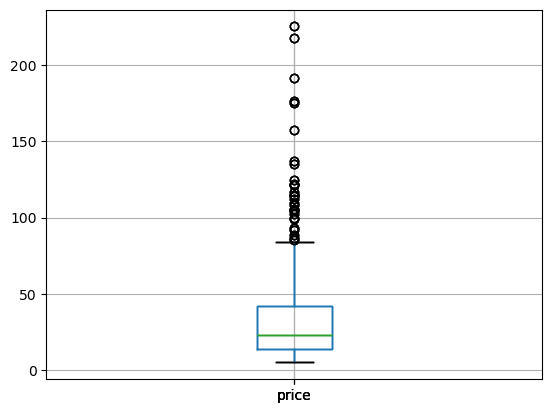

In [ ]:
#Création d'une boîte à moustache de la répartition des prix grâce à Pandas
df_final.boxplot(column='price')
plt.show()

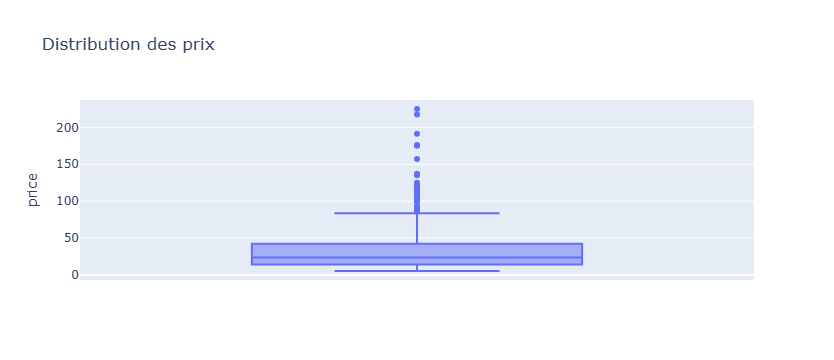

In [ ]:
#Autre méthode avec plotly express

fig = px.box(df_final, y='price', title='Distribution des prix')
fig.show()

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 4.2 - Exploration par l'utilisation de méthodes statistiques</h3>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 4.2.1 - Identification par le Z-index</h3>
</div>

In [ ]:
#Calculer la moyenne du prix
mean_price = df_final['price'].mean()
print("Moyenne des prix :", mean_price)
#Calculer l'écart-type du prix
std_price = df_final['price'].std()
print("Écart-type des prix :", std_price)
#Calculer le Z-score
df_final['z_score'] = (df_final['price'] - mean_price) / std_price

Moyenne des prix : 32.31661991584853
Écart-type des prix : 27.611935508393085


In [ ]:
#Quel est le seuil prix dont le z-score est supérieur à 3?
outliers_z = df_final[df_final['z_score'] > 3]
outliers_z
outliers_z['price'].min()

116.4

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 4.2.2 - Identification par l'intervalle interquartile</h3>
</div>

In [ ]:
#Utilisation de la fonction "describe" de Pandas pour l'étude des mesures de dispersion
df_final['price'].describe()

count    713.000000
mean      32.316620
std       27.611936
min        5.200000
25%       14.050000
50%       23.400000
75%       42.000000
max      225.000000
Name: price, dtype: float64

In [ ]:
#Définir un seuil pour les articles "outliers" en prix
Q1 = df_final['price'].quantile(0.25)
Q3 = df_final['price'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Seuil bas :", lower_bound)
print("Seuil haut :", upper_bound)

Seuil bas : -27.874999999999996
Seuil haut : 83.925


In [ ]:
#Définir le nombre d'articles et la proportion de l'ensemble du catalogue "outliers"
nb_outliers = len(outliers_iqr)
print("Nombre d'outliers :", nb_outliers)
proportion = nb_outliers / len(df_final)
print("Proportion d'outliers :", proportion)
print("Proportion (%) :", proportion * 100)

Nombre d'outliers : 31
Proportion d'outliers : 0.043478260869565216
Proportion (%) : 4.3478260869565215


In [ ]:
#Selon vous, ces outliers sont-ils justifiés ? Comment le démontrer si cela est possible ?
# Analyse des outliers

# L’analyse des produits identifiés comme outliers montre qu’il s’agit
# de références haut de gamme, telles que des champagnes,
# des grands crus ou des cognacs premium.

# Les prix d’achat associés sont également élevés,
# ce qui confirme la cohérence des prix de vente.
outliers_iqr[['post_title', 'price', 'purchase_price']].sort_values(by='price', ascending=False)
outliers_iqr[['price', 'purchase_price']]

,price,purchase_price
63,100.0,52.70
65,88.4,44.30
199,225.0,137.81
205,85.6,51.93
218,176.0,78.25
219,108.5,52.22
221,157.0,69.08
222,104.0,46.71
227,109.6,53.80
380,102.3,51.80


<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 5 - Analyse univariée du CA, des quantités vendues, des stocks et de la marge ainsi qu'une analyse multivariée  </h2>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 5.1 - Analyse des ventes en CA</h3>
</div>

In [ ]:
##############################
# Calculer le CA du site web #
##############################

#Créer une colonne calculant le CA par article
df_final['ca_par_article'] = df_final['price'] * df_final['total_sales']
#Calculer la somme de la colonne "ca_par_article"
#Ce résultat correspond au chiffre d'affaire du site web
ca_total = df_final['ca_par_article'].sum()
print("Chiffre d'affaires total :", round(ca_total, 2))

Chiffre d'affaires total : 143324.1


In [ ]:
###############################
# Palmarès des articles en CA #
###############################

#Effectuer le tri dans l'ordre décroissant du CA du dataset df_merge
df_ca = df_final.sort_values(by='ca_par_article', ascending=False)
#Réinitialiser l'index du dataset par un reset_index
df_ca = df_ca.reset_index(drop=True)
#Afficher les 20 premiers articles en CA
df_ca.head(20)[['post_title', 'price', 'total_sales', 'ca_par_article']]
#Graphique en barre des 20 premiers articles avec plotly express
top20_ca = df_ca.head(20)

fig = px.bar(
    top20_ca.sort_values(by='ca_par_article'),  # important pour affichage propre
    x='ca_par_article',
    y='post_title',
    orientation='h',
    title='Top 20 des articles par chiffre d’affaires',
    labels={'post_title': 'Article', 'ca_par_article': 'CA par article'}
)

fig.show()


In [ ]:
#############################
# Calculer le 20 / 80 en CA #
#############################

#Créer une colonne calculant la part du CA de la ligne dans le dataset
df_ca['part_ca'] = df_ca['ca_par_article'] / df_ca['ca_par_article'].sum()
#Créer une colonne réalisant la somme cumulative de la colonne précedemment créée
df_ca['cumule_ca'] = df_ca['part_ca'].cumsum()
#Grâce aux deux colonnes créées précedemment, calculer le nombre d'articles représentant 80% du CA
top_80 = df_ca[df_ca['cumule_ca'] <= 0.8]
#Afficher la proportion que représente ce groupe d'articles dans le catalogue entier du site web
nb_top80 = len(top_80)
print("Nombre d'articles pour 80% du CA :", nb_top80)
proportion_top80 = nb_top80 / len(df_ca)
print("Proportion des articles :", proportion_top80)
print("Proportion (%) :", proportion_top80 * 100)

Nombre d'articles pour 80% du CA : 433
Proportion des articles : 0.6072931276297335
Proportion (%) : 60.72931276297335


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 5.2 - Analyse des ventes en quantité</h3>
</div>

In [ ]:
#####################################
# Palmarès des articles en quantité #
#####################################

#Effectuer le tri dans l'ordre décroissant de quantités vendues du dataset df_merge
df_qte = df_final.sort_values(by='total_sales', ascending=False)
#Réinitialiser l'index du dataset par un reset_index
df_qte = df_qte.reset_index(drop=True)
#Afficher les 20 premiers articles en quantité
df_qte.head(20)[['post_title', 'total_sales', 'price']]
#Graphique en barre des 20 premiers articles avec plotly express
top20_qte = df_qte.head(20)

fig = px.bar(
    top20_qte.sort_values(by='total_sales'),
    x='total_sales',
    y='post_title',
    orientation='h',
    title='Top 20 des articles par quantités vendues',
    labels={'post_title': 'Article', 'total_sales': 'Quantité vendue'}
)

fig.show()

In [ ]:
#############################
# Calculer le 20 / 80 en CA #
#############################

#Créer une colonne calculant la part en quantité de la ligne dans le dataset
df_qte['part_qte'] = df_qte['total_sales'] / df_qte['total_sales'].sum()
#Créer une colonne réalisant la somme cumulative de la colonne précedemment créée
df_qte['cumule_qte'] = df_qte['part_qte'].cumsum()
#Grâce aux deux colonnes créées précedemment, calculer le nombre d'articles représentant 80% des ventes en quantité
top_80_qte = df_qte[df_qte['cumule_qte'] <= 0.8]
nb_top80_qte = len(top_80_qte)
print("Nombre d'articles représentant 80% des ventes :", nb_top80_qte)
#Afficher la proportion que représente ce groupe d'articles dans le catalogue entier du site web
proportion_top80_qte = nb_top80_qte / len(df_qte)
print("Proportion dans le catalogue :", round(proportion_top80_qte, 4))
print("Proportion (%) :", round(proportion_top80_qte * 100, 2), "%")

Nombre d'articles représentant 80% des ventes : 432
Proportion dans le catalogue : 0.6059
Proportion (%) : 60.59 %


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 5.3 - Analyse des stocks</h3>
</div>

In [ ]:
######################################
# Calculer le nombre de mois de stock #
######################################

#Import de numpy 
#deja fais avant
#Création de la colonne Rotation de stock
df_final['mois_stock'] = df_final['stock_quantity'] / df_final['total_sales']
#Remplacement des "inf" par 0
df_final['mois_stock'] = df_final['mois_stock'].replace([np.inf, -np.inf], 0)
#Effectuer le tri dans l'ordre décroissant du nombre de mois de stock dans le dataset df_merge
df_stock = df_final.sort_values(by='mois_stock', ascending=False)
#Graphique en barre du flop 20 des produits qui ont le plus de mois de stock
#flop20_stock = df_stock.head(20)
fig = px.bar(
    flop20_stock.sort_values(by='mois_stock'),
    x='mois_stock',
    y='post_title',
    orientation='h',
    title='Top 20 des produits avec le plus de mois de stock',
    labels={'post_title': 'Produit', 'mois_stock': 'Mois de stock'}
)

fig.show()

In [ ]:
####################################
# Valorisation des stocks en euros #
####################################

#Création de la colonne Valorisation des stocks en euros
df_final['Valorisation_stock_euros'] = df_final['purchase_price'] * df_final['stock_quantity']
#Calculer la somme de la colonne "Valorisation_stock_euros"
valeur_stock = df_final['Valorisation_stock_euros'].sum()
print("Valorisation totale du stock :", round(valeur_stock, 2))

Valorisation totale du stock : 277328.07


In [ ]:
##############################################
# Valorisation du nombre de produits en stock #
##############################################

#Calculer la somme de la colonne stock quantity
total_stock = df_final['stock_quantity'].sum()
print("Nombre total de produits en stock :", total_stock)

Nombre total de produits en stock : 16740


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 5.4 - Analyse du taux de marge</h3>
</div>

In [ ]:
############################
# Analyse du taux de marge #
############################

#Création de la colonne Prix HT
df_final['prix_ht'] = df_final['price'] / 1.2
#Création de la colonne Taux de marge
df_final['taux_marge'] = (df_final['prix_ht'] - df_final['purchase_price']) / df_final['purchase_price']
#Afficher le prix minimum de la colonne "taux_marge"
print("Taux de marge minimum :", round(df_final['taux_marge'].min(), 2))
#Afficher le prix maximum de la colonne "taux_marge"
print("Taux de marge maximum :", round(df_final['taux_marge'].max(), 2))

Taux de marge minimum : -0.86
Taux de marge maximum : 0.91


In [ ]:
#Affichage de la ligne avec un taux de marge inférieur à 0
df_final[df_final['taux_marge'] < 0][['post_title', 'price', 'purchase_price', 'taux_marge']]

,post_title,price,purchase_price,taux_marge
201,Champagne Egly-Ouriet Grand Cru Blanc de Noirs,12.65,77.48,-0.863943


In [ ]:
#Création d'un dataframe avec les taux positifs
df_marge_positive = df_final[df_final['taux_marge'] > 0]
#Afficher le prix minimum de la colonne "taux_marge"
print("Taux de marge minimum :", round(df_marge_positive['taux_marge'].min(), 2))
#Afficher le prix maximum de la colonne "taux_marge"
print("Taux de marge maximum :", round(df_marge_positive['taux_marge'].max(), 2))

Taux de marge minimum : 0.29
Taux de marge maximum : 0.91


In [ ]:
#Création d'un dataframe avec le taux de marge moyen par type de produit
df_marge_type = df_final.groupby('post_type')['taux_marge'].mean().reset_index()
df_marge_type
#Affichage dans un graphique du taux de marge par type de produit
fig = px.bar(
    df_marge_type,
    x='post_type',
    y='taux_marge',
    title='Taux de marge moyen par type de produit',
    labels={'post_type': 'Type de produit', 'taux_marge': 'Taux de marge moyen'}
)

fig.show()

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 5.5 - Analyse des corrélations entre les variables stock, sales et price</h3>
</div>

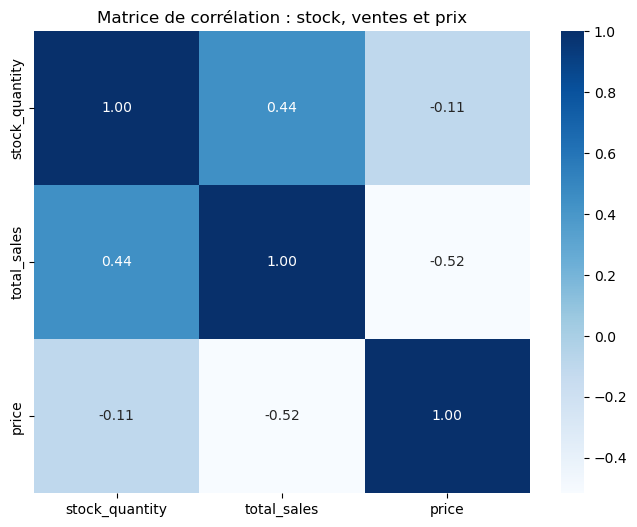

In [ ]:
############################
# Analyse des corrélations #
############################

#Importation de Seaborn

#Création d'une heatmap de corrélation avec les variables stock, sales et price
#On peut également créer un mask pour n'afficher qu'une demi heatmap
corr_matrix = df_final[['stock_quantity', 'total_sales', 'price']].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='Blues', fmt='.2f')
plt.title("Matrice de corrélation : stock, ventes et prix")
plt.show()

In [ ]:
#Que peut-on conclure des corrélations ?
# Les résultats montrent que :
# - Les ventes diminuent lorsque le prix augmente, ce qui est cohérent avec le comportement des clients.
# - Les produits qui se vendent le plus ont généralement plus de stock.
# - En revanche, le prix n’a pas d’impact direct sur le niveau de stock.

# Conclusion : le prix influence les ventes, et le stock semble être ajusté en fonction de la demande.

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 5.6 - Mise à disposition de la nouvelle table sur un fichier Excel</h3>
</div>

In [ ]:
#Mettre le dataset df_merge sur un fichier Excel
df_final.to_excel("bottleneck_dataset_final.xlsx", index=False)
#Cette étape peut être utile pour partager le résultat du dataset obtenu avec les équipes.  
# Export du dataset final
import os
print(os.getcwd())
# Le dataset final a été exporté en format Excel
# afin de faciliter son partage avec les équipes.

C:\Users\ines2
